## Installation of Required Libraries

In [ ]:
!pip install -q pyspark

## Importing Libraries and Loading the E-Commerce Sales Dataset

In [ ]:
from pyspark.sql import SparkSession
from google.colab import files
import os

uploaded = files.upload()

file_path = next(iter(uploaded.keys()))

spark = SparkSession.builder \
    .appName("AmazonSalesAnalysis") \
    .getOrCreate()

df = spark.read.csv(
    file_path,
    header=True,
    inferSchema=True
)

print("Total records:", df.count())
print("Total columns:", len(df.columns))

df.show(5, truncate=False)

Saving Amazon_Sales_2025_INR.csv to Amazon_Sales_2025_INR.csv
Total records: 15000
Total columns: 17
+---------+----------+-----------+----------------+------------+--------+--------------+---------------+-------------+----------------+---------------+-------------+-----------------+-------------+------------------+---------+-------+
|Order_ID |Date      |Customer_ID|Product_Category|Product_Name|Quantity|Unit_Price_INR|Total_Sales_INR|Net_Sales_INR|Payment_Method  |Delivery_Status|Extra_Charges|Return Amount_INR|Review_Rating|Review_Text       |State    |Country|
+---------+----------+-----------+----------------+------------+--------+--------------+---------------+-------------+----------------+---------------+-------------+-----------------+-------------+------------------+---------+-------+
|ORD100000|25-01-2025|CUST2796   |Home & Kitchen  |Cookware Set|2       |25574         |51149          |150          |Credit Card     |Returned       |150          |50999            |1.0        

## Data Quality Assessment: Missing Values, Duplicate Records, and Schema Inspection

In [ ]:

from pyspark.sql.functions import col, sum as spark_sum

# 1. Check missing values
print("Missing values in each column:")

df.select([
    spark_sum(
        col(c).isNull().cast("int")
    ).alias(c)
    for c in df.columns
]).show()

# 2. Check duplicate rows
total_rows = df.count()
unique_rows = df.dropDuplicates().count()

print("Total rows:", total_rows)
print("Duplicate rows:", total_rows - unique_rows)

# 3. Display column names and data types
df.printSchema()


Missing values in each column:
+--------+----+-----------+----------------+------------+--------+--------------+---------------+-------------+--------------+---------------+-------------+-----------------+-------------+-----------+-----+-------+
|Order_ID|Date|Customer_ID|Product_Category|Product_Name|Quantity|Unit_Price_INR|Total_Sales_INR|Net_Sales_INR|Payment_Method|Delivery_Status|Extra_Charges|Return Amount_INR|Review_Rating|Review_Text|State|Country|
+--------+----+-----------+----------------+------------+--------+--------------+---------------+-------------+--------------+---------------+-------------+-----------------+-------------+-----------+-----+-------+
|       0|   0|          0|               0|           0|       0|             0|              0|            0|             0|              0|            0|                0|            0|          0|    0|      0|
+--------+----+-----------+----------------+------------+--------+--------------+---------------+------------

## Data Cleaning and Preprocessing

In [ ]:

from pyspark.sql.functions import col, to_date

# Remove exact duplicate rows
clean_df = df.dropDuplicates()

# Convert Date from text to date format
clean_df = clean_df.withColumn(
    "Date",
    to_date(col("Date"), "dd-MM-yyyy")
)

# Remove rows with missing essential values
clean_df = clean_df.dropna(
    subset=["Order_ID", "Date", "Product_Category",
            "Quantity", "Total_Sales_INR"]
)

# Check the cleaned data
print("Rows before cleaning:", df.count())
print("Rows after cleaning:", clean_df.count())

clean_df.printSchema()
clean_df.show(5, truncate=False)


Rows before cleaning: 15000
Rows after cleaning: 15000
root
 |-- Order_ID: string (nullable = true)
 |-- Date: date (nullable = true)
 |-- Customer_ID: string (nullable = true)
 |-- Product_Category: string (nullable = true)
 |-- Product_Name: string (nullable = true)
 |-- Quantity: integer (nullable = true)
 |-- Unit_Price_INR: integer (nullable = true)
 |-- Total_Sales_INR: integer (nullable = true)
 |-- Net_Sales_INR: integer (nullable = true)
 |-- Payment_Method: string (nullable = true)
 |-- Delivery_Status: string (nullable = true)
 |-- Extra_Charges: integer (nullable = true)
 |-- Return Amount_INR: integer (nullable = true)
 |-- Review_Rating: double (nullable = true)
 |-- Review_Text: string (nullable = true)
 |-- State: string (nullable = true)
 |-- Country: string (nullable = true)

+---------+----------+-----------+----------------+------------+--------+--------------+---------------+-------------+--------------+---------------+-------------+-----------------+-------------+

## Overall Sales Performance Analysis

In [ ]:

from pyspark.sql.functions import sum, avg, count

clean_df.select(
    sum("Total_Sales_INR").alias("Total Sales (INR)"),
    sum("Net_Sales_INR").alias("Net Sales (INR)"),
    avg("Review_Rating").alias("Average Rating"),
    count("*").alias("Total Records")
).show()


+-----------------+---------------+------------------+-------------+
|Total Sales (INR)|Net Sales (INR)|    Average Rating|Total Records|
+-----------------+---------------+------------------+-------------+
|       1118161916|      981786144|3.0401333333333334|        15000|
+-----------------+---------------+------------------+-------------+



## Product Category Sales and Quantity Analysis

In [ ]:

from pyspark.sql.functions import desc

category_sales = clean_df.groupBy("Product_Category") \
    .agg(
        sum("Total_Sales_INR").alias("Total_Sales"),
        sum("Quantity").alias("Total_Quantity")
    ) \
    .orderBy(desc("Total_Sales"))

category_sales.show(truncate=False)


+----------------+-----------+--------------+
|Product_Category|Total_Sales|Total_Quantity|
+----------------+-----------+--------------+
|Beauty          |227489659  |9090          |
|Electronics     |226564938  |9072          |
|Books           |224999244  |8950          |
|Clothing        |222409354  |8924          |
|Home & Kitchen  |216698721  |8734          |
+----------------+-----------+--------------+



## State-Wise Sales Performance Analysis

In [ ]:

state_sales = clean_df.groupBy("State") \
    .agg(
        sum("Total_Sales_INR").alias("Total_Sales")
    ) \
    .orderBy(desc("Total_Sales"))

state_sales.show(10, truncate=False)


+-------------+-----------+
|State        |Total_Sales|
+-------------+-----------+
|Sikkim       |43113463   |
|Rajasthan    |42906173   |
|Chhattisgarh |42857551   |
|Meghalaya    |42773163   |
|Tamil Nadu   |41967976   |
|Uttar Pradesh|41690938   |
|Bihar        |41669249   |
|West Bengal  |41195931   |
|Tripura      |41103395   |
|Odisha       |40924382   |
+-------------+-----------+
only showing top 10 rows


## Monthly Sales Trend Analysis

In [ ]:

from pyspark.sql.functions import date_format

monthly_sales = clean_df.withColumn(
    "Month", date_format("Date", "yyyy-MM")
).groupBy("Month").agg(
    sum("Total_Sales_INR").alias("Monthly_Sales")
).orderBy("Month")

monthly_sales.show(20, truncate=False)


+-------+-------------+
|Month  |Monthly_Sales|
+-------+-------------+
|2025-01|92051805     |
|2025-02|84995761     |
|2025-03|93064358     |
|2025-04|91388987     |
|2025-05|97195856     |
|2025-06|89730702     |
|2025-07|95176927     |
|2025-08|97576560     |
|2025-09|91225559     |
|2025-10|93478366     |
|2025-11|94809197     |
|2025-12|97467838     |
+-------+-------------+



## Visualization of Sales by Product Category

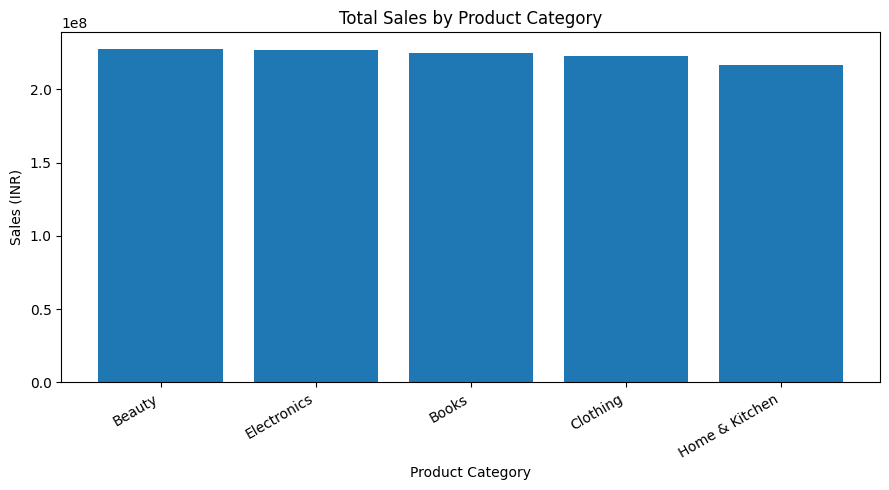

In [ ]:

import matplotlib.pyplot as plt

category_pd = category_sales.toPandas()

plt.figure(figsize=(9, 5))
plt.bar(
    category_pd["Product_Category"],
    category_pd["Total_Sales"]
)
plt.title("Total Sales by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Sales (INR)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


## Visualization of Top 10 States by Total Sales

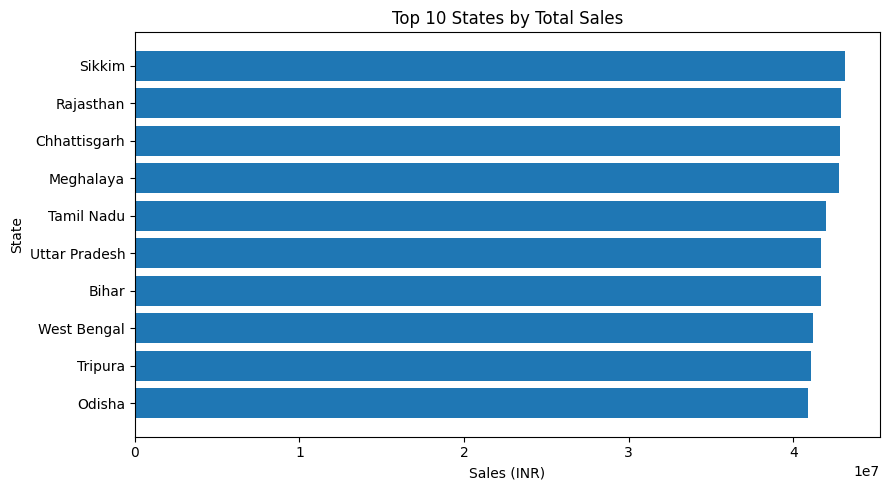

In [ ]:

state_pd = state_sales.limit(10).toPandas()

plt.figure(figsize=(9, 5))
plt.barh(
    state_pd["State"],
    state_pd["Total_Sales"]
)
plt.title("Top 10 States by Total Sales")
plt.xlabel("Sales (INR)")
plt.ylabel("State")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


## Visualization of Monthly Sales Trends

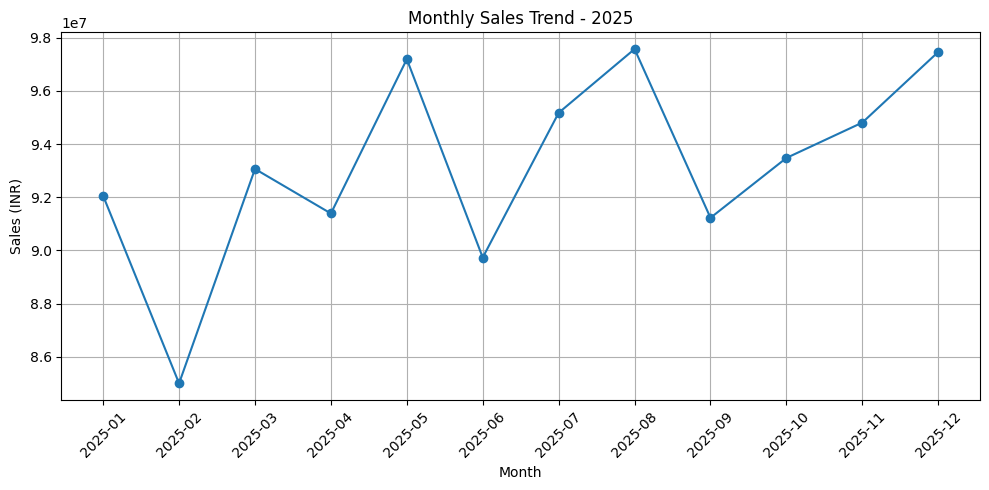

In [ ]:

monthly_pd = monthly_sales.toPandas()

plt.figure(figsize=(10, 5))
plt.plot(
    monthly_pd["Month"],
    monthly_pd["Monthly_Sales"],
    marker="o"
)
plt.title("Monthly Sales Trend - 2025")
plt.xlabel("Month")
plt.ylabel("Sales (INR)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()


## Exporting Sales Analysis Results to CSV Files

In [ ]:

category_sales.toPandas().to_csv(
    "category_sales.csv", index=False
)

state_sales.toPandas().to_csv(
    "state_sales.csv", index=False
)

monthly_sales.toPandas().to_csv(
    "monthly_sales.csv", index=False
)

print("Analysis results saved successfully!")


Analysis results saved successfully!


## Payment Method Analysis

In [ ]:

from pyspark.sql.functions import sum, count, desc

payment_analysis = clean_df.groupBy("Payment_Method").agg(
    count("*").alias("Total_Orders"),
    sum("Total_Sales_INR").alias("Total_Sales")
).orderBy(desc("Total_Orders"))

payment_analysis.show(truncate=False)


+----------------+------------+-----------+
|Payment_Method  |Total_Orders|Total_Sales|
+----------------+------------+-----------+
|Cash on Delivery|3827        |286511443  |
|Credit Card     |3800        |286889304  |
|Debit Card      |3727        |273036616  |
|UPI             |3646        |271724553  |
+----------------+------------+-----------+



## Delivery Status Analysis

In [ ]:

delivery_analysis = clean_df.groupBy("Delivery_Status").agg(
    count("*").alias("Total_Orders"),
    sum("Total_Sales_INR").alias("Total_Sales")
).orderBy(desc("Total_Orders"))

delivery_analysis.show(truncate=False)


+---------------+------------+-----------+
|Delivery_Status|Total_Orders|Total_Sales|
+---------------+------------+-----------+
|Delivered      |13182       |981458194  |
|Returned       |1818        |136703722  |
+---------------+------------+-----------+



## Visualization of Orders by Payment Method

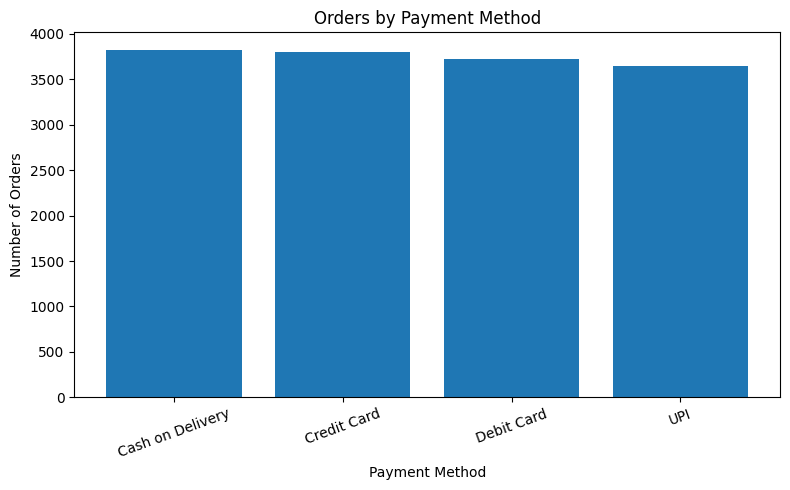

In [ ]:

import matplotlib.pyplot as plt

payment_pd = payment_analysis.toPandas()

plt.figure(figsize=(8, 5))
plt.bar(
    payment_pd["Payment_Method"],
    payment_pd["Total_Orders"]
)
plt.title("Orders by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Number of Orders")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


## Visualization of Orders by Delivery Status

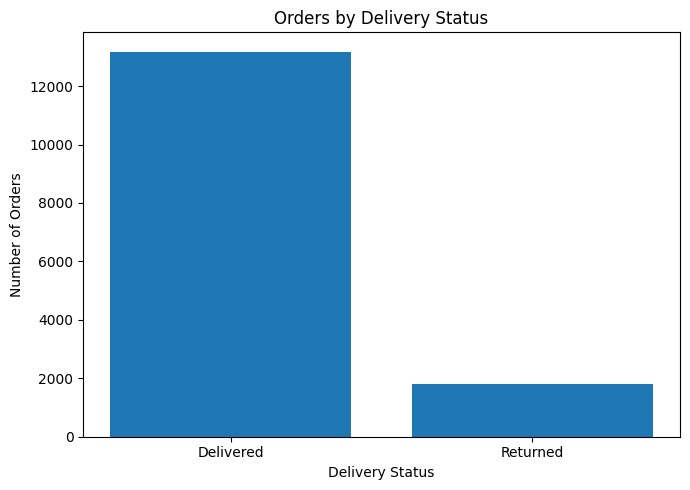

In [ ]:

delivery_pd = delivery_analysis.toPandas()

plt.figure(figsize=(7, 5))
plt.bar(
    delivery_pd["Delivery_Status"],
    delivery_pd["Total_Orders"]
)
plt.title("Orders by Delivery Status")
plt.xlabel("Delivery Status")
plt.ylabel("Number of Orders")
plt.tight_layout()
plt.show()
